Mounted at /content/drive/
/content/drive/My Drive/Colab Notebooks/DL2022/cats


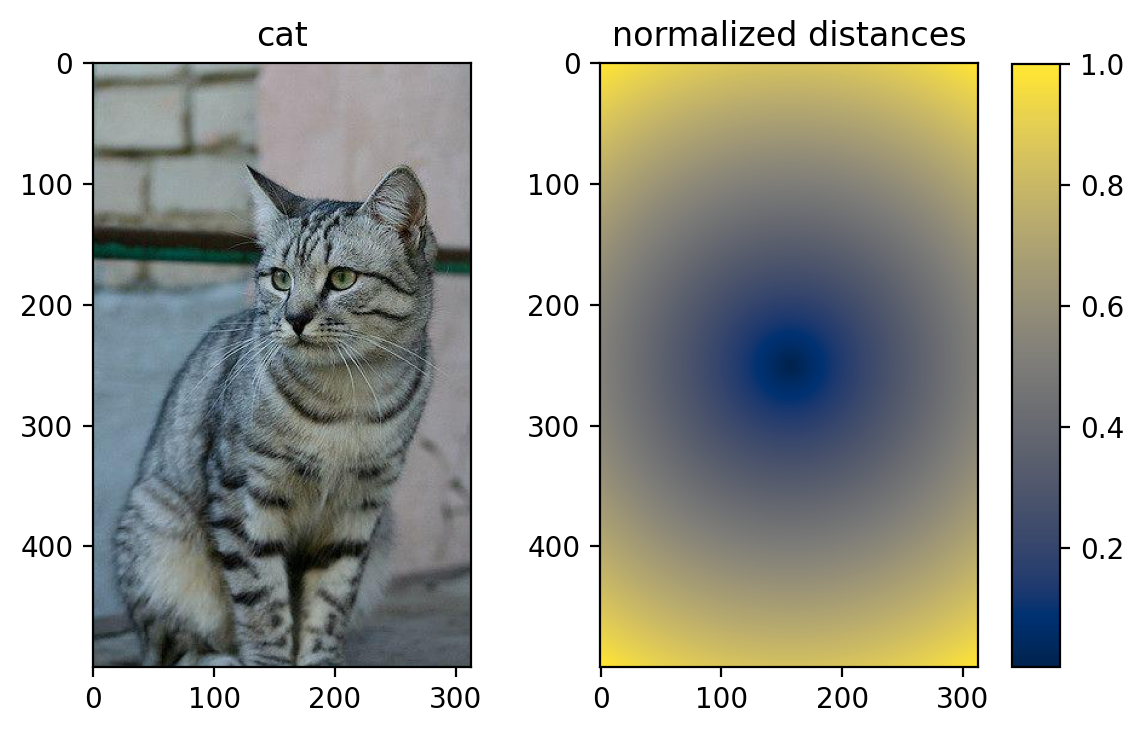

In [2]:
from google.colab import drive

import numpy as np
drive.mount("/content/drive/")
import imageio
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image
%cd /content/drive/My Drive/Colab Notebooks/DL2022/cats/


##EX 1.2
# map pixel location to normalized distance to the image center
def radius_map(I):
    W, H = (I.shape[1], I.shape[0]) # if I is RGB it has a third dimension 
    # shift the origin to the middle of the image
    wc = W / 2
    hc = H / 2
    xv, yv = np.meshgrid(np.arange(W) - wc, np.arange(H) - hc)
    r = np.sqrt(xv ** 2 + yv ** 2)      # euclidean distance from the center
    r = r / np.sqrt(wc ** 2 + hc ** 2)  # normalize corner to distance 1
    return r

# demo of the radius map
fig, axs = plt.subplots(1, 2, dpi=200)
I = Image.open("cat_01.jpg")         # load and decompress JPEG into a PIL Image
axs[0].imshow(I)
axs[0].set_title("cat")

# print radius map (a bit messy to force matplotlib to keep the size and ratio)
I = np.asarray(I, dtype=np.float32) # cast uint8 image to numpy float32 array
rm = axs[1].imshow(radius_map(I), cmap="cividis")
axs[1].set_title("normalized distances")

cb_ax = fig.add_axes([.91, .124, .04, .754])
fig.colorbar(rm, cax=cb_ax)
fig.show()

In [3]:
# helper funciton : reshape image to W*H by 4 matrix (RGB + distance from center)
def I2X(I): 
    W, H = (I.shape[1], I.shape[0])
    r = radius_map(I)

    X = np.zeros((W * H, 4), dtype=np.float32)
    X[:, 0] = np.ravel(I[:, :, 0]) # R component
    X[:, 1] = np.ravel(I[:,:, 1])  # G component
    X[:, 2] = np.ravel(I[:, :, 2]) # B component
    X[:, 3] = np.ravel(r)          # distance from image center
    return X


# evaluate polynomial (given by coefficients a[0],....,a[n]) on a radius map r
def polynom_map(a, r):
      s = a[0] * np.ones_like(r)
      for deg in range(1, len(a)):
        s += a[deg] * (r ** deg)
        return s

# apply vignetting to an image I as defined by model coefficients a[0],...,a[n]
def vignetting(I, a):
        r = radius_map(I)
        s = polynom_map(a, r)

        J = np.zeros(I.shape, np.float32)
        J[:, :, 0] = s * I[:, :, 0]
        J[:, :, 1] = s * I[:, :, 1]
        J[:, :, 2] = s * I[:, :, 2]
        return J

# remove vignetting from image I as defined by model coefficients a[0],...,a[n]
def devignetting(I, a):
        r = radius_map(I)
        s = polynom_map(a, r)

        J = np.zeros(I.shape, np.float32)
        J[:, :, 0] = I[:, :, 0] / s
        J[:, :, 1] = I[:, :, 1] / s
        J[:, :, 2] = I[:, :, 2] / s
        return J 

max float32 error:  1.1920929e-07 
max uint8 error:  0


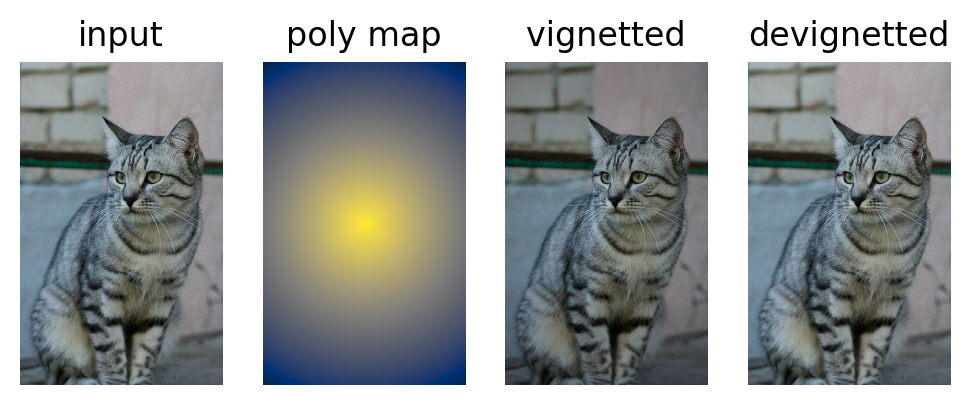

In [4]:
# demo of the vignetting effect
fig, ax = plt.subplots(1, 4, dpi=200)
for a in ax:
    a.set_axis_off()

I = Image.open("cat_01.jpg")
ax[0].imshow(I)
ax[0].set_title("input")

I = np.asarray(I, dtype=np.float32)
# dummy coefficients from the vignetting_example.py:
a = [1.0, -0.3, 0.05, -0.25, -0.4, -0.05, 0.1]

# visualize effects of the model
ax[1].imshow(polynom_map(a, radius_map(I)), cmap="cividis")
ax[1].set_title("poly map")


# visual effects of the model on the cat
J = vignetting(I, a)
ax[2].imshow(J / 255)   # rescale floats to [0, 1] for imshow
ax[2].set_title("vignetted")

# visualize effects of the devignetting
K = devignetting(J, a)
ax[3].imshow(K / 255)
ax[3].set_title("devignetted")

fig.show()

float32_error = np.max(np.abs( I / 255 - K / 255))
uint8_error = np.max(np.abs( (I / 255). astype("uint8") - (K / 255).astype("uint8") ))
print("max float32 error: ", float32_error, "\nmax uint8 error: ", uint8_error)

In [5]:
# Load training data 
# helper: read image, reorganize data and add distance map
def load_data(x):
  x = Image.open(x)
  x = np.asarray(x, dtype=np.float32)
  x = I2X(x)
  return x

# lists of paths with training pairs
X_files = ["cat_01.jpg", "cat_02.jpg", "cat_03.jpg"]
Y_files = ["cat_01_vignetted.jpg", "cat_02_vignetted.jpg", "cat_03_vignetted.jpg"]

# np arrays of data
X = np.concatenate([load_data(x) for x in X_files])
Y = np.concatenate([load_data(x) for x in Y_files])

# print shapes to check if they agree
display(X.shape)
display(Y.shape)

(469500, 4)

(469500, 4)

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:9: RuntimeWarning: invalid value encountered in true_divide
  if __name__ == '__main__':


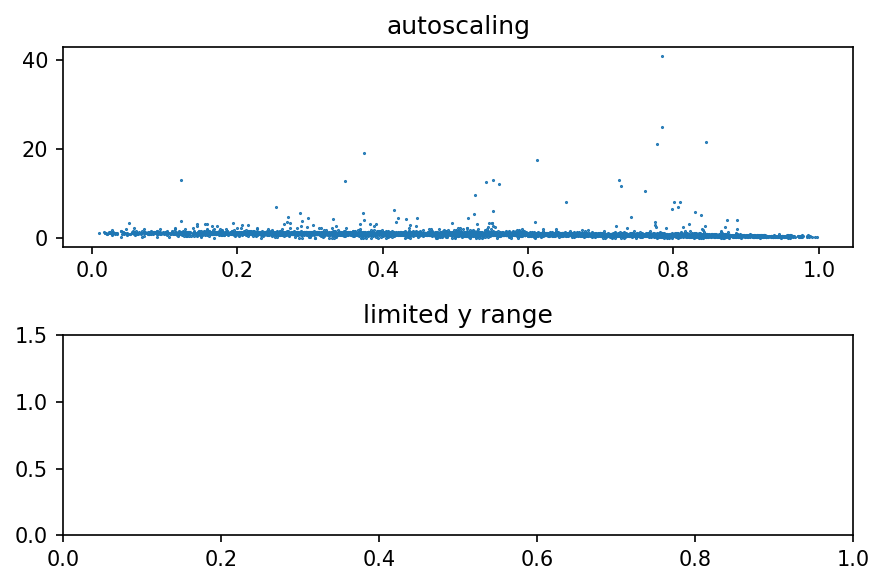

In [6]:
# Randomize dataset
perm = np.random.permutation(X.shape[0])
X = X[perm, :]
Y = Y[perm, :]

# show a random sample
plot_sample = 7500
with np.errstate(divide="ignore"):
  q = Y[0:plot_sample, 0] / X[0:plot_sample, 0]
r = X[0:plot_sample, 3]

fig, ax = plt.subplots(2, 1, dpi=150)
ax[0].scatter(r, q, marker=".", s=1)
ax[0].set_title("autoscaling")
ax[1].set_ylim([0, 1.5])
ax[1].set_title("limited y range")
plt.tight_layout()
plt.show()

In [7]:
def loss(a, x, y):
  s = polynom_map(a, x[:, 3]) # components 0-2 is RGB data, [3] is the radius
  # calculate mean squared error between predictions on x (using params a) and y
  mse = tf.reduce_mean((s*x[:,0] - y[:,0])**2 + (s*x[:,1] - y[:,1])**2 + (s*x[:,2] - y[:,2])**2)
  return mse

def training(Xt, Yt, Xv, Yv, a0, lam=0, lr=0.001, epochs=100, print_interval=10):
  # cast initial model parameters for usage with TF
  # I'll stick to calling the coefficient array "a" here as we did above,
  # generally model parameters are often called theta
  a = [tf.Variable(t) for t in a0]

  opt = tf.kera.optimizers.SGD(lr)
  #opt = tf.keras.optimizers.Nadam(lr) # another optimizer to try

  # log training and validation losses over the epochs
  training_log = []
  validation_log = []

  for epoch in range(epochs):
    # calculate gradients on the training set
    with tf.GradientTape() as tape:
      losst = loss(a, Xt, Yt)
      # optionally: regularize model parameters with lam > 0
      reg_losst = losst + lam * tf.math.reduce_sum([a_n ** 2 for a_n in a])

    # we only need validation loss but no gradients
    lossv = loss(a, Xv, Yv)

    grads = tape.gradient(reg_losst, a)
    opt.apply_gradients(zip(grads, a))
    if epoch % print_interval == 0:
      print("Epoch %d, training loss: %f, validatin loss: %f" % (epoch, float(losst), float(lossv)))

    training_log.append(float(losst))
    validation_log.apppend(float(lossv))

  return ([np.float32(x) for x in a], training_log, validation_log) 

In [11]:
# hand-crafted 5-fold split
n = X.shape[0] # total number of training samples (image pixels)
K = 5          # number of splits

degrees = range(1, 10) # poly degree
epochs = 300


# training and validation losses
training_loss_log = []
validation_loss_log = []
thetas = []

for deg in degrees:
  # try each of the K training / validation splits
  print("##### DEGREE %d #####" % deg)
  for k in [1]: #range(K):
    print("##### SPLIT %d ####" % k)
    vstart = k * int(n/K)
    vstop = (k+1) * int(n/K)
    # indexng for the validation chunk
    Xv = X[vstart:vstop, :]
    Yv = Y[vstart:vstop, :]
    # the rest remains for training
    Xt = X[np.concatenate((np.arange(0, vstart), np.arange(vstop+1, n))), :]
    Yt = Y[np.concatenate((np.arange(0, vstart), np.arange(vstop+1, n))), :]

    # start with the zero polynomial of degree
    a0 = np.zeros(deg, dtype=np.float32)
    theta, training_losses, validation_losses = training(Xt, Yt, Xv, Yv, a0, lam=0, lr=1e-7, epochs=epochs, print_interval=10) # lambda=0 -> no regularization

    # leep loss logs and parameters
    training_loss_log.append(training_losses)
    validation_loss_log.append(validation_losses)
    while len(theta) < len(degrees):
      theta.append(0.0) # fill up with zeros to convert to numpy array
    thetas.append(theta)

# convert lists to np arrays for easier indexing
training_loss_log = np.array(training_loss_log)
validation_loss_log = np.array(validation_loss_log)
thetas = np.array(thetas)



##### DEGREE 1 #####
##### SPLIT 1 ####


AttributeError: ignored